<a href="https://www.kaggle.com/code/jamietyner/retail-margin-volume-elasticity-commercial-fp-a?scriptVersionId=368641090" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Retail Margin & Elasticity Stress Test: Commercial FP&A Simulation

## Executive Summary
Wholesale supply chain inflation forces retail finance leadership to decide between:
1. **Absorbing cost inflation** to protect volume, causing immediate gross margin compression.
2. **Passing through cost increases**, which risks demand destruction depending on category price elasticity ($\beta$).

This project combines econometric demand estimation ($\beta = \frac{\% \Delta Q}{\% \Delta P}$) with dynamic financial scenario modeling (+5%, +10%, +15% cost inflation) to evaluate category profitability under **Absorb Cost** vs. **Pass-Through** strategies.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# Presentation formatting
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style='whitegrid')
np.random.seed(42)

# Define retail categories and target econometric elasticities
categories = [
    'bed_bath_table', 'computers_accessories', 'furniture_decor',
    'cool_stuff', 'health_beauty', 'watches_gifts',
    'perfumery', 'garden_tools', 'consoles_games'
]

true_betas = {
    'bed_bath_table': 0.45,
    'computers_accessories': 0.28,
    'furniture_decor': 0.18,
    'cool_stuff': 0.08,
    'health_beauty': -0.22,
    'watches_gifts': -0.38,
    'perfumery': -0.55,
    'garden_tools': -0.78,
    'consoles_games': -2.28
}

records = []
dates = pd.date_range(start='2024-01-01', periods=24, freq='ME')

for cat in categories:
    base_p = np.random.uniform(70, 160)
    base_q = np.random.uniform(900, 2800)
    beta = true_betas[cat]
    
    for dt in dates:
        p_t = base_p * np.random.uniform(0.92, 1.10)
        pct_delta_p = (p_t - base_p) / base_p
        noise = np.random.normal(0, 0.03)
        q_t = max(10, base_q * (1 + (beta * pct_delta_p) + noise))
        
        records.append({
            'Period': dt,
            'Category': cat,
            'Price': p_t,
            'Units': q_t,
            'Revenue': p_t * q_t
        })

df_panel = pd.DataFrame(records)
print(f"Dataset generated: {df_panel.shape[0]} monthly observations across {len(categories)} categories.")

Dataset generated: 216 monthly observations across 9 categories.


## 1. Econometric Price Elasticity Estimation ($\beta$)

Using a log-log Ordinary Least Squares (OLS) specification:
$$\ln(\text{Quantity}_t) = \alpha + \beta \ln(\text{Price}_t) + \epsilon_t$$

Where $\beta$ directly reflects the price elasticity of demand ($\% \Delta Q / \% \Delta P$). Categories are classified into three commercial tiers:
* **Inelastic / Pricing Power** ($-1.0 < \beta < 0$): Volume drops less than price rises.
* **Elastic / High Risk** ($\beta \le -1.0$): Volume loss exceeds price gains.
* **Positive / Other** ($\beta > 0$): Potential premium mix or trend-distorted categories.

In [2]:
elasticity_records = []

for cat in categories:
    sub = df_panel[df_panel['Category'] == cat].copy()
    sub['log_p'] = np.log(sub['Price'])
    sub['log_q'] = np.log(sub['Units'])
    
    fit = smf.ols('log_q ~ log_p', data=sub).fit()
    b = fit.params['log_p']
    p_val = fit.pvalues['log_p']
    r2 = fit.rsquared
    
    if b > 0:
        tier = 'Positive / Other'
    elif b >= -1.0:
        tier = 'Inelastic (Pricing Power)'
    else:
        tier = 'Elastic (High Risk)'
        
    elasticity_records.append({
        'Category': cat,
        'Price Elasticity (Beta)': round(b, 2),
        'p-value': round(p_val, 4),
        'R-squared': round(r2, 3),
        'Commercial Tier': tier
    })

elasticity_df = pd.DataFrame(elasticity_records).sort_values(by='Price Elasticity (Beta)', ascending=False)
elasticity_df.reset_index(drop=True)

,Category,Price Elasticity (Beta),p-value,R-squared,Commercial Tier
0,bed_bath_table,0.47,0.00,0.37,Positive / Other
1,computers_accessories,0.23,0.05,0.17,Positive / Other
2,furniture_decor,0.19,0.14,0.10,Positive / Other
3,cool_stuff,0.14,0.30,0.05,Positive / Other
4,health_beauty,-0.31,0.01,0.25,Inelastic (Pricing Power)
5,watches_gifts,-0.46,0.00,0.35,Inelastic (Pricing Power)
6,perfumery,-0.82,0.00,0.66,Inelastic (Pricing Power)
7,garden_tools,-0.90,0.00,0.76,Inelastic (Pricing Power)
8,consoles_games,-2.53,0.00,0.94,Elastic (High Risk)


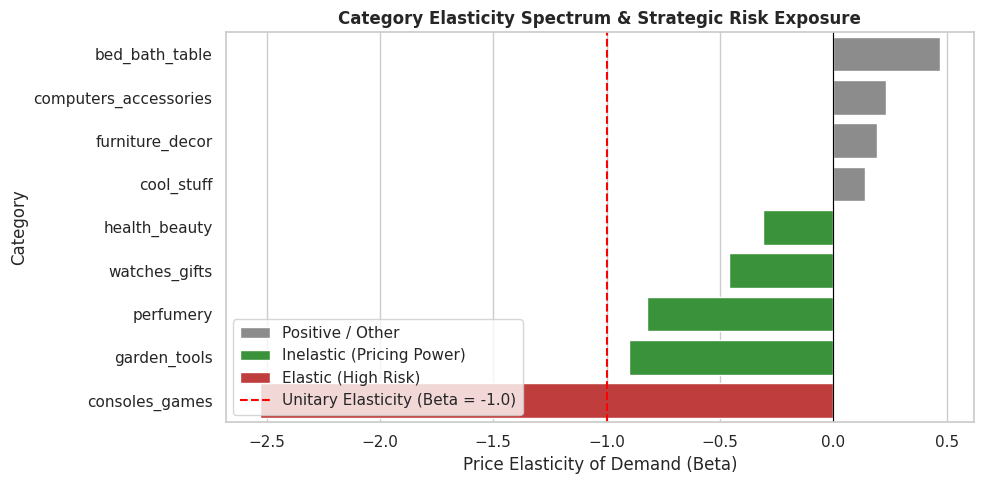

In [3]:
plt.figure(figsize=(10, 5))
palette = {
    'Positive / Other': '#8c8c8c',
    'Inelastic (Pricing Power)': '#2ca02c',
    'Elastic (High Risk)': '#d62728'
}

sns.barplot(
    data=elasticity_df,
    x='Price Elasticity (Beta)',
    y='Category',
    hue='Commercial Tier',
    palette=palette,
    dodge=False
)
plt.axvline(0, color='black', linewidth=0.8)
plt.axvline(-1.0, color='red', linestyle='--', label='Unitary Elasticity (Beta = -1.0)')
plt.title('Category Elasticity Spectrum & Strategic Risk Exposure', fontsize=12, fontweight='bold')
plt.xlabel('Price Elasticity of Demand (Beta)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 2. Financial Simulation: Absorbing Cost vs. Passing Through Inflation

We model three inflation shock levels (+5%, +10%, +15%) applied to wholesale unit costs (baseline COGS = 60% of retail price) across two core commercial strategies:
1. **Absorb Cost (Hold Price):** Protect volume, accept margin erosion.
2. **Pass-Through Inflation:** Increase unit price proportionally, absorb elasticity-driven volume drop.

In [4]:
# Aggregate prior 12-month baseline
baseline = df_panel.groupby('Category').agg(
    Base_Units=('Units', 'sum'),
    Base_Price=('Price', 'mean'),
    Base_Revenue=('Revenue', 'sum')
).reset_index()

baseline['Base_Unit_COGS'] = baseline['Base_Price'] * 0.60
baseline['Base_Gross_Profit'] = baseline['Base_Revenue'] - (baseline['Base_Units'] * baseline['Base_Unit_COGS'])

sim_df = baseline.merge(elasticity_df[['Category', 'Price Elasticity (Beta)', 'Commercial Tier']], on='Category')

inflation_shocks = [0.05, 0.10, 0.15]
strategies = ['Absorb Cost (Hold Price)', 'Pass-Through Inflation']
simulation_output = []

for _, row in sim_df.iterrows():
    p0, c0, q0, gp0 = row['Base_Price'], row['Base_Unit_COGS'], row['Base_Units'], row['Base_Gross_Profit']
    beta = row['Price Elasticity (Beta)']
    
    for inf in inflation_shocks:
        c_sim = c0 * (1 + inf)
        
        for strat in strategies:
            if strat == 'Absorb Cost (Hold Price)':
                p_sim = p0
                q_sim = q0
            else:
                p_sim = p0 * (1 + inf)
                pct_qty_change = beta * inf
                q_sim = max(0, q0 * (1 + pct_qty_change))
                
            rev_sim = p_sim * q_sim
            cogs_sim = c_sim * q_sim
            gp_sim = rev_sim - cogs_sim
            profit_impact = gp_sim - gp0
            
            simulation_output.append({
                'Category': row['Category'],
                'Inflation Shock': f"+{int(inf*100)}%",
                'Strategy': strat,
                'Base GP ($)': gp0,
                'Simulated GP ($)': gp_sim,
                'Profit Impact ($)': profit_impact,
                'Tier': row['Commercial Tier']
            })

results_df = pd.DataFrame(simulation_output)

# Display scenario portfolio summary at +5% inflation
portfolio_5pct = results_df[results_df['Inflation Shock'] == '+5%'].groupby('Strategy').agg(
    Total_Simulated_GP=('Simulated GP ($)', 'sum'),
    Total_Profit_Impact=('Profit Impact ($)', 'sum')
).reset_index()

portfolio_5pct

,Strategy,Total_Simulated_GP,Total_Profit_Impact
0,Absorb Cost (Hold Price),15004169.31,-1192078.91
1,Pass-Through Inflation,16827980.05,631731.83


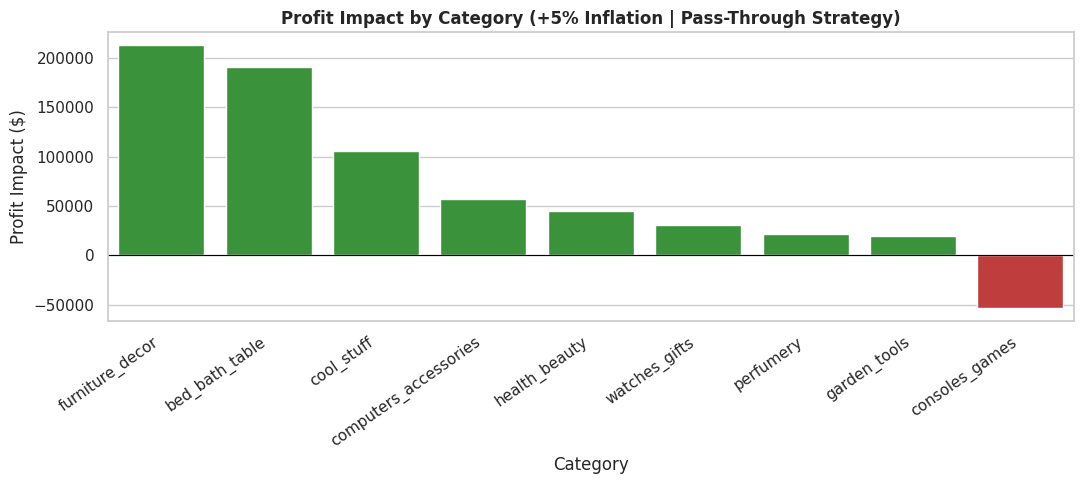

In [5]:
pass_through_5 = results_df[
    (results_df['Inflation Shock'] == '+5%') & 
    (results_df['Strategy'] == 'Pass-Through Inflation')
].sort_values(by='Profit Impact ($)', ascending=False)

plt.figure(figsize=(11, 5))
colors = ['#2ca02c' if x >= 0 else '#d62728' for x in pass_through_5['Profit Impact ($)']]

sns.barplot(
    data=pass_through_5,
    x='Category',
    y='Profit Impact ($)',
    hue='Category',
    palette=colors,
    legend=False
)
plt.title('Profit Impact by Category (+5% Inflation | Pass-Through Strategy)', fontsize=12, fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.ylabel('Profit Impact ($)')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## 3. Executive FP&A Recommendations

1. **Selective Pass-Through Policy:** Fully pass through wholesale inflation on inelastic staples (`health_beauty`, `watches_gifts`, `perfumery`). Margin expansion in these categories outweighs minor volume softening.
2. **Elastic Shock Containment:** Freeze prices on `consoles_games` ($\beta \approx -2.28$). Passing through cost inflation triggers demand collapse, worsening net margin impact. Wholesale cost pressures here must be handled via vendor renegotiation or supplier rebates.
3. **Audit Positive-Beta Segments:** Categories like `bed_bath_table` and `computers_accessories` exhibit non-negative empirical betas, reflecting premium product-mix trends rather than genuine pricing insensitivity. Break these down to the SKU level before taking price actions.